In [1]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

df = pd.read_excel("GSAF5.xls")
df_sex_age = df[["Sex", "Age"]].copy()
df_sex_age.shape

(7125, 2)

In [3]:
df_sex_age["Sex"].value_counts(dropna=False)


Sex
M        5709
F         818
NaN       578
M           8
?           2
F           2
N           2
M F         1
 M          1
m           1
lli         1
M x 2       1
.           1
Name: count, dtype: int64

In [4]:
df_sex_age["Sex"] = df_sex_age["Sex"].str.strip().str.upper()

df_sex_age["Sex"] = df_sex_age["Sex"].replace({
    "M X 2": "M"
})

df_sex_age["Sex"] = df_sex_age["Sex"].where(df_sex_age["Sex"].isin(["M", "F"]), "Unknown")

df_sex_age["Sex"].value_counts(dropna=False)


Sex
M          5720
F           820
Unknown     585
Name: count, dtype: int64

Se eliminan espacios y se unifican mayúsculas. "M x 2" se asigna a M por tratarse de dos hombres en el mismo registro. Los valores "N", "M F", "?", ".", "lli" y los vacíos no permiten saber el sexo con seguridad, por lo que se agrupan como "Unknown".

In [5]:
edad_num = pd.to_numeric(df_sex_age["Age"], errors="coerce")

print("Vacíos:", df_sex_age["Age"].isna().sum())
print("No numéricos:", (edad_num.isna() & df_sex_age["Age"].notna()).sum())


Vacíos: 2994
No numéricos: 179


In [6]:
df_sex_age.loc[edad_num.isna() & df_sex_age["Age"].notna(), "Age"].astype(str).value_counts().head(60)


Age
?                 38
30s               12
Teen              11
20s               10
50s                6
40s                5
teen               4
20's               3
60s                3
50's               2
30+                2
8 or 10            2
                   2
7 or 8             2
young              2
50+                1
40+                1
60+                1
Middle age         1
20/30              1
!2                 1
M                  1
!6                 1
!!                 1
45 and 15          1
28 & 22            1
22, 57, 31         1
9 & 60             1
a minor            1
40?                1
18 months          1
28 & 26            1
18 or 20           1
12 or 13           1
46 & 34            1
28, 23 & 30        1
Teens              1
36 & 26            1
                   1
30 or 36           1
6½                 1
21 & ?             1
33 or 37           1
mid-30s            1
23 & 20            1
7      &    31     1
20?                1
60's     

In [7]:
import re
import numpy as np

def limpiar_edad(x):
    if pd.isna(x):
        return np.nan

    s = str(x).strip().lower()
    s = re.sub(r"!(?=\d)", "1", s)   # !2 -> 12
    s = s.replace("½", ".5")          # 6½ -> 6.5

    if "&" in s or " and " in s or "," in s:
        return np.nan

    if "month" in s:
        n = re.findall(r"\d+", s)
        return round(int(n[0]) / 12, 2) if n else np.nan

    if "teen" in s:
        return 15.0

    decada = re.fullmatch(r"(?:mid-)?(\d+)'?s", s)
    if decada:
        return float(decada.group(1)) + 5

    nums = re.findall(r"\d+\.?\d*", s)
    if len(nums) == 1:
        return float(nums[0])
    if len(nums) == 2:
        return (float(nums[0]) + float(nums[1])) / 2

    return np.nan


In [8]:
df_sex_age["Age_clean"] = df_sex_age["Age"].apply(limpiar_edad)

texto = edad_num.isna() & df_sex_age["Age"].notna()
df_sex_age.loc[texto, ["Age", "Age_clean"]].astype(str).value_counts().head(60)


Age            Age_clean
30s            35.0         12
Teen           15.0         11
20s            25.0         10
50s            55.0          6
40s            45.0          5
teen           15.0          4
20's           25.0          3
60s            65.0          3
50's           55.0          2
30+            30.0          2
8 or 10        9.0           2
7 or 8         7.5           2
50+            50.0          1
40+            40.0          1
60+            60.0          1
20/30          25.0          1
!2             12.0          1
!6             16.0          1
40?            40.0          1
18 months      1.5           1
18 or 20       19.0          1
12 or 13       12.5          1
Teens          15.0          1
30 or 36       33.0          1
6½             6.5           1
33 or 37       35.0          1
mid-30s        35.0          1
20?            20.0          1
60's           65.0          1
16 to 18       17.0          1
mid-20s        25.0          1
Ca. 33        

In [9]:
print("Nulos antes (to_numeric a lo bruto):", edad_num.isna().sum())
print("Nulos ahora:", df_sex_age["Age_clean"].isna().sum())
df_sex_age["Age_clean"].describe()


Nulos antes (to_numeric a lo bruto): 3173
Nulos ahora: 3077


count    4048.000000
mean       28.215519
std        14.744851
min         0.170000
25%        17.000000
50%        24.000000
75%        37.000000
max        87.000000
Name: Age_clean, dtype: float64

## Limpieza de Age
La columna Age tenía valores vacíos y textos que no se podían convertir directamente a número. Para no perder esos datos, se creó la función limpiar_edad con estos criterios:
- **Décadas** ("30s", "mid-30s") → mitad de la década (35). **"Teen"** → 15.
- **Rangos** ("8 or 10", "16 to 18") → media de los dos valores.
- **Símbolos** ("30+", ">50", "Ca. 33") → se toma el número. **Meses** ("18 months") → años (1.5).
- **Errores de escritura**: "!2" → 12 ("!" y "1" están en la misma tecla).
- **Varias personas** ("28 & 22") o **textos sin número** ("?", "young", "adult") → NaN.

El resultado se guardó en Age_clean para compararlo con el valor original. Después se comprobó que se recuperan edades y que todos los valores están en un rango razonable.


**ANÁLISIS**

In [10]:
df["Sex"] = df_sex_age["Sex"]
df["Age"] = df_sex_age["Age_clean"]

df_mf = df[df["Sex"].isin(["M", "F"])]


In [11]:
tabla_sexo = pd.DataFrame({
    "Ataques": df["Sex"].value_counts(),
    "%": (df["Sex"].value_counts(normalize=True) * 100).round(2)
})
tabla_sexo


,Ataques,%
Sex,,
M,5720,80.28
F,820,11.51
Unknown,585,8.21


El 80,3% de los ataques registrados corresponden a hombres, el 11,5% a mujeres y el 8,2% son de sexo desconocido. Si solo se tienen en cuenta los casos con sexo conocido, el 87,5% son hombres y el 12,5% mujeres: por cada mujer atacada hay unos 7 hombres.

In [12]:
tabla_sexo = pd.DataFrame({
    "Ataques": df["Sex"].value_counts(),
    "%": (df["Sex"].value_counts(normalize=True) * 100).round(2)
})
tabla_sexo


,Ataques,%
Sex,,
M,5720,80.28
F,820,11.51
Unknown,585,8.21


In [13]:
df_mf.groupby("Sex")["Age"].agg(["count", "mean", "median", "min", "max"]).round(1)



,count,mean,median,min,max
Sex,,,,,
F,606,27.9,22.0,0.8,85.0
M,3407,28.3,25.0,1.0,87.0


La edad media es casi igual en ambos sexos (27,9 años en mujeres y 28,3 en hombres). Sin embargo, la mediana es menor en mujeres (22 frente a 25), lo que indica que las mujeres atacadas tienden a ser algo más jóvenes. Solo 4.013 de los registros de hombres y mujeres tienen edad, por lo que las conclusiones sobre la edad se basan en algo más de la mitad de los casos.


In [14]:
df["Age_group"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 30, 45, 60, 100],
    labels=["0-12", "13-18", "19-30", "31-45", "46-60", "60+"],
    include_lowest=True
)
df["Age_group"].value_counts().sort_index()


Age_group
0-12      355
13-18     895
19-30    1372
31-45     846
46-60     438
60+       142
Name: count, dtype: int64

El grupo con más ataques es el de 19-30 años (1.372 casos), seguido de 13-18 años (895). Entre los 13 y los 30 años se concentra el 56% de los ataques con edad registrada. A partir de los 45 años los ataques bajan mucho, probablemente porque estas personas practican menos actividades acuáticas de riesgo.


In [15]:
df_mf = df[df["Sex"].isin(["M", "F"])]

pd.crosstab(df_mf["Age_group"], df_mf["Sex"], margins=True, margins_name="Total")


Sex,F,M,Total
Age_group,,,
0-12,99,253,352
13-18,136,746,882
19-30,150,1210,1360
31-45,119,722,841
46-60,71,365,436
60+,31,111,142
Total,606,3407,4013


El grupo con más ataques es el de 19-30 años (1.372 casos), seguido de 13-18 años (895). Entre los 13 y los 30 años se concentra el 56% de los ataques con edad registrada. A partir de los 45 años los ataques bajan mucho, probablemente porque estas personas practican menos actividades acuáticas de riesgo.


In [16]:
(pd.crosstab(df_mf["Age_group"], df_mf["Sex"], normalize="columns") * 100).round(1)

Sex,F,M
Age_group,,
0-12,16.3,7.4
13-18,22.4,21.9
19-30,24.8,35.5
31-45,19.6,21.2
46-60,11.7,10.7
60+,5.1,3.3


En números absolutos los hombres superan a las mujeres en todos los grupos de edad. En porcentajes dentro de cada sexo aparecen diferencias:
- En hombres, los ataques se concentran en los 19-30 años (35,5%).
- En mujeres el reparto es más uniforme, y el porcentaje de niñas de 0-12 años (16,3%) es más del doble que el de niños (7,4%).
- Entre los 13 y los 18 años el porcentaje es prácticamente igual en ambos sexos (22%).


In [17]:
df.columns


Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22', 'Age_group'],
      dtype='str')

In [18]:
(pd.crosstab(df_mf["Sex"], df_mf["Type"], normalize="index") * 100).round(1)


Type,Provoked,?,Invalid,Provoked,Questionable,Sea Disaster,UNprovoked,Under investigation,Unprovoked,Unverified,Watercraft,unprovoked
Sex,,,,,,,,,,,,
F,0.0,0.0,8.0,3.8,0.5,1.1,0.0,0.1,85.4,0.0,1.1,0.0
M,0.0,0.0,7.2,9.7,0.4,2.9,0.0,0.0,77.1,0.0,2.5,0.0


La mayoría de los ataques son no provocados en ambos sexos, pero en mujeres el porcentaje es mayor (85,4% frente a 77,1%). Los ataques provocados son más del doble en hombres (9,7% frente a 3,8%), lo que puede deberse a que los hombres realizan más actividades como pesca o manipulación de tiburones.

In [19]:
df_mf["Fatal Y/N"].value_counts(dropna=False)

Fatal Y/N
N          4615
Y          1385
NaN         480
UNKNOWN      40
 N            7
F             5
M             3
n             1
Nq            1
2017          1
Y x 2         1
y             1
Name: count, dtype: int64

In [20]:
fatal = df_mf["Fatal Y/N"].str.strip().str.upper().replace({"Y X 2": "Y"})
fatal = fatal.where(fatal.isin(["Y", "N"]), "Unknown")
fatal.value_counts()

Fatal Y/N
N          4623
Y          1387
Unknown     530
Name: count, dtype: int64

In [21]:
mf_conocido = df_mf[fatal != "Unknown"]
fatal_conocido = fatal[fatal != "Unknown"]

(pd.crosstab(mf_conocido["Sex"], fatal_conocido, normalize="index") * 100).round(1)

Fatal Y/N,N,Y
Sex,,
F,83.3,16.7
M,76.0,24.0


In [22]:
(pd.crosstab(mf_conocido["Age_group"], fatal_conocido, normalize="index") * 100).round(1)

Fatal Y/N,N,Y
Age_group,,
0-12,87.9,12.1
13-18,80.9,19.1
19-30,80.4,19.6
31-45,82.1,17.9
46-60,81.4,18.6
60+,77.7,22.3


In [23]:
mf_conocido.groupby(fatal_conocido)["Age"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
Fatal Y/N,,,
N,3072,28.0,24.0
Y,696,28.8,24.0


## Análisis de mortalidad
Se normaliza la columna Fatal Y/N (espacios, minúsculas, "Y x 2" → Y) y los valores que no se pueden interpretar ("UNKNOWN", "F", "M", "2017", "Nq" y vacíos) se agrupan como Unknown. Estos casos (530) se excluyen de los porcentajes. De los 6.010 ataques restantes, 1.387 fueron mortales, un **23,1%**.

**Mortalidad por sexo**
- Los ataques a hombres son más mortales: el **24%** fue mortal, frente al **16,7%** en mujeres.
- Puede deberse a que los hombres practican más actividades de riesgo (pesca, buceo, surf en aguas abiertas) y sufren más ataques provocados.

**Mortalidad por grupo de edad**
- Los niños de **0-12 años** tienen la mortalidad más baja (**12,1%**).
- Los mayores de **60 años** tienen la más alta (**22,3%**), posiblemente por una menor capacidad de reacción y de recuperación.
- Entre los 13 y los 60 años la mortalidad es estable, entre el 18% y el 20%.

**Edad de las víctimas según mortalidad**
- La edad media es casi igual en ataques mortales (28,8 años) y no mortales (28,0), y la mediana es la misma (24 años). La edad por sí sola no marca una gran diferencia en la mortalidad, salvo en los extremos (niños y mayores de 60).

**Observación:** en los registros con edad conocida la mortalidad es del 18,5% (696 de 3.768), menor que el 23,1% general. Los ataques sin edad registrada son más mortales, probablemente porque muchos son casos antiguos con poca información y peor atención médica. Por eso los resultados por edad pueden subestimar algo la mortalidad real.


In [24]:
print("Vacíos:", df["Activity"].isna().sum())
print("Valores distintos:", df["Activity"].nunique())
df["Activity"].str.strip().str.lower().value_counts().head(40)


Vacíos: 583
Valores distintos: 1617


Activity
surfing                    1162
swimming                   1075
fishing                     514
spearfishing                405
wading                      178
bathing                     167
diving                      155
snorkeling                  138
standing                    115
scuba diving                106
body boarding                70
boogie boarding              60
body surfing                 55
kayaking                     44
free diving                  35
treading water               33
fell overboard               33
pearl diving                 32
surf skiing                  24
windsurfing                  20
floating                     18
canoeing                     17
walking                      17
kayak fishing                16
shark fishing                16
playing                      14
surf fishing                 14
sea disaster                 14
rowing                       14
surf-skiing                  13
freediving                   12

In [25]:
categorias = [
    ("Spearfishing",       r"spear"),
    ("Fishing",            r"fish|\bnet|clam|crab|lobster|shrimp|shell|scallop|opihi|beche"),
    ("Shark interaction",  r"shark"),
    ("Sea disaster",       r"sank|sunk|sink|capsiz|wreck|overboard|disaster|ship|fell into|plane|aircraft|crash|swamp|freighter"),
    ("Diving",             r"div|scuba|snorkel"),
    ("Kayak/Paddle",       r"kayak|kakay|canoe|rowing|paddl|scull|\bsup\b"),
    ("Boat",               r"sail|boat|watercraft|cruis|racing|launch|yacht|dighy|motor"),
    ("Surfing/Board",      r"surf|board|boogie|kite|foil|ski"),
    ("Swimming",           r"swim|bath|float|tread|splash|adrift"),
    ("Wading/Standing",    r"wad|stand|walk|play|jump|sitting|dangling|wash|squat|kneel|crouch|lying|crawl"),
]

def limpiar_actividad(x):
    if pd.isna(x):
        return "Unknown"
    s = str(x).strip().lower()
    if s in ["", "?", ".", "unknown", "not stated", "undisclosed"]:
        return "Unknown"
    for nombre, patron in categorias:
        if re.search(patron, s):
            return nombre
    return "Other"


In [26]:
df["Activity_clean"] = df["Activity"].apply(limpiar_actividad)
df["Activity_clean"].value_counts()

Activity_clean
Surfing/Board        1559
Swimming             1453
Fishing               953
Diving                682
Unknown               596
Spearfishing          516
Wading/Standing       412
Sea disaster          388
Shark interaction     165
Kayak/Paddle          160
Other                 151
Boat                   90
Name: count, dtype: int64

In [27]:
df.loc[df["Activity_clean"] == "Other", "Activity"].str.strip().str.lower().value_counts().head(40)

Activity
murder                                                               6
lifesaving drill                                                     4
escaping from alacatraz                                              3
suicide                                                              3
filming                                                              2
operation of rescue torpedo                                          1
rescuing female companion                                            1
military ocean training                                              1
on a round-the-world expedition                                      1
towing a dead whale out to sea                                       1
watching the sardine run                                             1
lifeguard training exercise                                          1
lifeguard exercises                                                  1
fihing                                                              

## Limpieza de Activity
La columna Activity tenía más de 1.600 valores distintos escritos en texto libre. Se agruparon en categorías buscando palabras clave (regex) en un orden de prioridad: por ejemplo, "spearfishing" se revisa antes que "fishing", y "surf fishing" cuenta como pesca y no como surf. También se corrigieron erratas ("fihing", "kakaying", "batin"). Los vacíos y los textos sin información ("unknown", "not stated") se agrupan como Unknown, y los casos muy raros que no encajan en ninguna categoría (asesinatos, rescates, investigación…) como Other.


In [28]:
actividad = df.loc[df["Activity_clean"] != "Unknown", "Activity_clean"]

tabla_actividad = pd.DataFrame({
    "Ataques": actividad.value_counts(),
    "%": (actividad.value_counts(normalize=True) * 100).round(1)
})
tabla_actividad

,Ataques,%
Activity_clean,,
Surfing/Board,1559,23.9
Swimming,1453,22.3
Fishing,953,14.6
Diving,682,10.4
Spearfishing,516,7.9
Wading/Standing,412,6.3
Sea disaster,388,5.9
Shark interaction,165,2.5
Kayak/Paddle,160,2.5


In [29]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


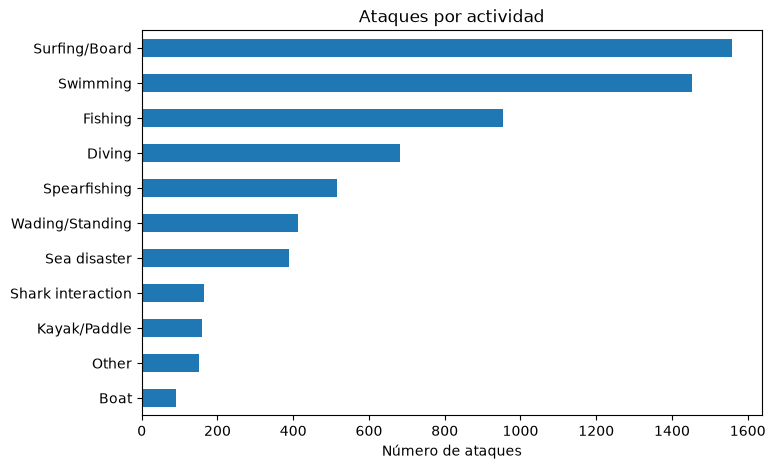

In [31]:
import matplotlib.pyplot as plt

tabla_actividad["Ataques"].sort_values().plot(kind="barh", figsize=(8, 5), title="Ataques por actividad")
plt.xlabel("Número de ataques")
plt.ylabel("")
plt.show()


## Análisis de actividades
Sin contar los registros de actividad desconocida (596), quedan 6.529 ataques:
- **Surfing/Board** es la actividad con más ataques (23,9%), seguida de **Swimming** (22,3%). Entre las dos suman casi la mitad de los casos (46%). Son las actividades más populares y en las que más tiempo se pasa en la superficie del agua, justo en la zona donde caza el tiburón.
- **Fishing** (14,6%) y **Spearfishing** (7,9%) suman un 22,5%. La pesca atrae a los tiburones por la sangre y los peces capturados, así que es una actividad de riesgo aunque se practique menos que el surf o la natación.
- **Diving** representa el 10,4%. Si se suma la pesca submarina, las actividades bajo el agua llegan al 18,3%.
- **Wading/Standing** (6,3%): estar de pie o caminando en aguas poco profundas, también tiene riesgo.
- **Sea disaster** (5,9%): naufragios y accidentes aéreos, donde las víctimas quedan en el agua durante horas.
- **Shark interaction** (2,5%): ataques al alimentar, marcar, provocar o intentar matar tiburones. Son ataques claramente provocados.
- **Kayak/Paddle** (2,5%), **Boat** (1,4%) y **Other** (2,3%) tienen muy pocos casos.

Conclusión: el riesgo se concentra en actividades de superficie (surf y natación) y en la pesca. Para una aseguradora, surfistas, nadadores y pescadores serían los perfiles con más exposición a un ataque de tiburón.


In [32]:
df_mf = df[df["Sex"].isin(["M", "F"])]
mf_conocido = df_mf[fatal != "Unknown"]
fatal_conocido = fatal[fatal != "Unknown"]

In [33]:
(pd.crosstab(df_mf["Activity_clean"], df_mf["Sex"], normalize="columns") * 100).round(1)

Sex,F,M
Activity_clean,,
Boat,0.9,1.0
Diving,11.8,9.8
Fishing,3.7,13.3
Kayak/Paddle,3.2,2.0
Other,0.9,2.0
Sea disaster,2.1,5.5
Shark interaction,2.9,2.1
Spearfishing,1.2,8.5
Surfing/Board,16.0,24.4


**Actividad según sexo**
- Las mujeres sufren la mayoría de los ataques mientras nadan (33%), están de pie o caminan en la orilla (16,6%) o hacen surf (16%). Son sobre todo actividades cerca de la costa.
- En los hombres la actividad principal es el surf (24,4%), seguido de la natación (20,1%), y tienen mucho más peso la pesca (13,3% frente a 3,7%) y la pesca submarina (8,5% frente a 1,2%).
- Los hombres también aparecen más en naufragios (5,5% frente a 2,1%).
- Los hombres hacen más actividades en aguas abiertas y de riesgo. Eso explica en parte que sufran más ataques y que estos sean más mortales.

In [34]:
(pd.crosstab(df_mf["Activity_clean"], df_mf["Age_group"], normalize="columns") * 100).round(1)

Age_group,0-12,13-18,19-30,31-45,46-60,60+
Activity_clean,,,,,,
Boat,0.6,0.5,0.7,1.0,0.7,0.7
Diving,3.7,5.2,8.8,14.0,16.5,13.4
Fishing,4.5,5.7,6.7,12.6,14.4,12.0
Kayak/Paddle,0.3,1.2,2.0,2.4,3.9,4.2
Other,2.0,0.3,1.1,1.3,0.5,2.8
Sea disaster,1.7,1.1,2.1,2.6,0.9,2.1
Shark interaction,2.3,1.0,1.9,2.4,1.8,2.1
Spearfishing,0.9,3.9,12.5,12.0,5.7,4.9
Surfing/Board,18.5,38.0,34.0,27.7,26.6,14.8


**Actividad según edad**
- **Niños (0-12):** se bañan (34,4%) o están en la orilla (24,1%). Son ataques en aguas poco profundas.
- **Adolescentes (13-18):** el surf es la actividad principal (38%).
- **Jóvenes (19-30):** sigue dominando el surf (34%) y aparece con fuerza la pesca submarina (12,5%).
- **Adultos (31-60):** suben mucho el buceo (14-16,5%) y la pesca (12,6-14,4%), y baja el surf.
- **Mayores de 60:** vuelve a predominar la natación (30,3%) y el surf cae al 14,8%.
- El tipo de actividad cambia con la edad: de jugar en la orilla en la infancia, al surf en la juventud y al buceo y la pesca en la edad adulta.

In [35]:
(pd.crosstab(mf_conocido["Activity_clean"], fatal_conocido, normalize="index") * 100).round(1).sort_values("Y", ascending=False)

Fatal Y/N,N,Y
Activity_clean,,
Sea disaster,29.8,70.2
Other,53.5,46.5
Boat,54.2,45.8
Swimming,63.7,36.3
Unknown,72.5,27.5
Diving,76.1,23.9
Fishing,81.6,18.4
Spearfishing,84.9,15.1
Wading/Standing,86.2,13.8


**Mortalidad según actividad**
- Los **naufragios y accidentes aéreos** son con diferencia lo más mortal (70,2%), porque las víctimas pasan horas en el agua, a menudo heridas y sin posibilidad de ayuda.
- **Boat** (45,8%) y **Swimming** (36,3%) también tienen una mortalidad alta. Un nadador no tiene nada con lo que protegerse y suele estar más lejos de ayuda que alguien en la orilla.
- El **surf** es la actividad con más ataques pero la **menos mortal** (7,7%). La tabla de surf hace de barrera, el surfista puede salir rápido del agua y suele haber gente cerca para ayudar.
- La pesca (18,4%), la pesca submarina (15,1%) y la interacción con tiburones (12,3%) tienen una mortalidad media-baja. Muchos son mordiscos defensivos del tiburón.

In [36]:
df_mf.groupby("Activity_clean")["Age"].agg(["count", "mean", "median"]).round(1).sort_values("count", ascending=False)

,count,mean,median
Activity_clean,,,
Surfing/Board,1232,26.7,23.0
Swimming,930,26.4,21.0
Diving,388,34.5,32.0
Fishing,343,33.8,33.0
Spearfishing,340,30.3,28.0
Wading/Standing,326,23.5,18.0
Unknown,156,24.2,20.0
Kayak/Paddle,82,35.3,32.0
Shark interaction,74,28.8,26.0


**Edad según actividad**
- Las víctimas más jóvenes están en Wading/Standing (mediana de 18 años) y Swimming (21), que coinciden con los ataques a niños y adolescentes en la orilla.
- Las víctimas de buceo (32), pesca (33) y kayak (32) son claramente mayores. Son actividades que requieren más equipo, experiencia o licencia.
- El surf queda en medio, con una mediana de 23 años.

## Conclusiones: Sexo, Edad, Mortalidad y Actividad
- **Frecuencia y gravedad no van juntas:** el surf es la actividad con más ataques pero la menos mortal (7,7%). Los naufragios son pocos, pero 7 de cada 10 acaban en muerte.
- **La natación es el perfil de mayor riesgo:** combina muchos ataques (22,3%) con una mortalidad alta (36,3%).
- **Los hombres** hacen más actividades en aguas abiertas (pesca, pesca submarina, surf, naufragios), lo que explica que sufran el 87,5% de los ataques y una mortalidad mayor (24% frente a 16,7%).
- **Mujeres y niños** sufren los ataques sobre todo en la orilla y nadando cerca de la costa.
- **La edad cambia la actividad de riesgo:** orilla en la infancia, surf en la juventud, buceo y pesca en adultos.
- **Para una aseguradora:** los nadadores en aguas abiertas, los pescadores y los tripulantes de barcos serían los perfiles con más riesgo de ataque grave. Los surfistas tienen muchos incidentes, pero de baja gravedad.
- **Limitación:** la mortalidad de algunas actividades (sobre todo natación y naufragios) puede estar inflada por casos antiguos, cuando la atención médica era peor.